# Assignment 6: Deep Convolutional Neural Network (CNN) for Tomato Leaf Disease Classification
## Computer Vision Pipeline for Automated Plant Pathology Detection

**Course:** Deep Learning Laboratory  
**Frameworks:** TensorFlow 2.x, Keras, NumPy, Matplotlib  
**Dataset:** Tomato Leaf Disease Dataset (Healthy and Multiple Pathological Classes)  

---

### 🎯 Objectives
1. **Computer Vision in Agriculture:** Automate the identification of tomato leaf diseases using deep convolutional networks.
2. **Dataset Ingestion Pipeline:** Stream large image directories efficiently using `tf.keras.utils.image_dataset_from_directory` with automatic batching and shuffling.
3. **Image Normalization:** Scale raw RGB pixel values from $[0, 255]$ to the standard float interval $[0.0, 1.0]$.
4. **Hierarchical CNN Architecture:** Design multi-stage feature extraction blocks consisting of `Conv2D` and `MaxPooling2D` layers to learn low-level edges, mid-level textures, and high-level lesion patterns.
5. **Regularization:** Integrate `Dropout(0.5)` to reduce co-adaptation and prevent overfitting on training leaf samples.
6. **Optimization & Training:** Compile with `Adam` and `categorical_crossentropy` and train over $20$ epochs.
7. **Diagnostic Visualization & Inference:** Graph training and validation accuracy/loss dynamics, perform single-image inference with visual validation, and serialize the trained model (`tomato_disease_cnn.keras`).

## 1. Import Libraries

We import:
- `tensorflow` and `tensorflow.keras.layers`, `models`: Deep learning primitives for 2D convolutions, pooling, activation functions, and sequential modeling.
- `numpy`: Tensor operations and array manipulations.
- `matplotlib.pyplot`: Image rendering and training trajectory visualization.

In [ ]:
# ============================================================
# Assignment 6
# Design and Implement a CNN for Tomato Disease Classification
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

## 2. Load the Tomato Dataset from Directory Structure

We stream images from disk using `image_dataset_from_directory()`:
- `IMG_SIZE = (128, 128)`: Standardizes varying image resolutions into a uniform $128 \times 128$ RGB tensor format.
- `BATCH_SIZE = 32`: Groups $32$ samples per gradient step.
- `label_mode='categorical'`: One-hot encodes the class labels for multi-class classification.
- Partitions the data into training (`train/`) and validation (`val/`) splits.

In [ ]:
# ============================================================
# Load the Dataset
# ============================================================

# Dataset paths
train_dir = "train"
val_dir = "val"

# Image parameters
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Load training dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
)

# Load validation dataset
val_dataset = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

# Get class names
class_names = train_dataset.class_names

print("Classes:")
print(class_names)

print("\nNumber of Classes:", len(class_names))

Found 10000 files belonging to 10 classes.
Found 984 files belonging to 10 classes.
Classes:
['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']

Number of Classes: 10


## 3. Data Preprocessing: Pixel Intensity Rescaling

Raw RGB pixels range from $0$ to $255$. We apply a `Rescaling(1./255)` layer to map inputs into $[0.0, 1.0]$.
This normalization accelerates gradient descent and prevents numeric overflow during convolution.

In [ ]:
# ============================================================
# Data Preprocessing
# ============================================================

# Normalize pixel values from 0-255 to 0-1
normalization_layer = layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

val_dataset = val_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

## 4. Build and Compile the Convolutional Neural Network (CNN)

### Feature Extraction Hierarchy:
1. **Conv Block 1 (32 Filters, $3\times 3$, ReLU) + MaxPool ($2\times 2$):** Captures low-level spatial features such as leaf edges, vein contours, and simple gradients.
2. **Conv Block 2 (64 Filters, $3\times 3$, ReLU) + MaxPool ($2\times 2$):** Aggregates low-level features into leaf surface textures and spot boundaries.
3. **Conv Block 3 (128 Filters, $3\times 3$, ReLU) + MaxPool ($2\times 2$):** Captures complex high-level representations distinguishing specific disease lesions (e.g., septoria spots, bacterial blights, leaf mold patterns).

### Classification Head:
- **`Flatten()`:** Converts 2D spatial feature maps into a 1D feature vector.
- **`Dense(128, activation='relu')`:** Fully connected decision layer.
- **`Dropout(0.5)`:** Zeroes out $50\%$ of hidden neurons randomly during training to enforce feature redundancy and prevent overfitting.
- **`Dense(num_classes, activation='softmax')`:** Outputs probability distribution across all tomato classes.

### Compilation:
- **Optimizer:** `Adam`
- **Loss Function:** `categorical_crossentropy`

In [ ]:
# ============================================================
# Build the CNN Model
# ============================================================

model = tf.keras.Sequential()

# Convolutional Layer 1
model.add(
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(128, 128, 3)
    )
)
model.add(layers.MaxPooling2D((2, 2)))

# Convolutional Layer 2
model.add(
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    )
)
model.add(layers.MaxPooling2D((2, 2)))

# Convolutional Layer 3
model.add(
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    )
)
model.add(layers.MaxPooling2D((2, 2)))

# Flatten feature maps
model.add(layers.Flatten())

# Fully connected hidden layer
model.add(layers.Dense(128, activation="relu"))

# Dropout to reduce overfitting
model.add(layers.Dropout(0.5))

# Output layer
model.add(
    layers.Dense(
        len(class_names),
        activation="softmax"
    )
)

# ============================================================
# Compile the Model
# ============================================================

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the CNN Model

We train the network for $20$ epochs, evaluating validation performance at the end of each epoch to track generalization.

In [ ]:
# ============================================================
# Train the CNN
# ============================================================

EPOCHS = 20

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 93ms/step - accuracy: 0.4582 - loss: 1.5361 - val_accuracy: 0.6921 - val_loss: 0.9015
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 95ms/step - accuracy: 0.6866 - loss: 0.8983 - val_accuracy: 0.6961 - val_loss: 0.8425
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 33s 105ms/step - accuracy: 0.7367 - loss: 0.7547 - val_accuracy: 0.7846 - val_loss: 0.5922
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 99ms/step - accuracy: 0.7777 - loss: 0.6325 - val_accuracy: 0.8130 - val_loss: 0.6002
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 99ms/step - accuracy: 0.7971 - loss: 0.5772 - val_accuracy: 0.8537 - val_loss: 0.3934
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 95ms/step - accuracy: 0.8262 - loss: 0.4873 - val_accuracy: 0.8730 - val_loss: 0.3988
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 100ms/step - accuracy: 0.8465 - loss: 0.4335 - val_accuracy: 0.8465 - val_loss: 0.4439
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 33s 105ms/step - accuracy: 0.8538 - loss: 0.4138

## 6. Model Evaluation on Validation Set

We compute overall loss and classification accuracy across all validation batches.

In [ ]:
# ============================================================
# Evaluate the Model
# ============================================================

test_loss, test_accuracy = model.evaluate(val_dataset)

print("\nValidation Loss:", test_loss)
print("Validation Accuracy:", test_accuracy)

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8222 - loss: 0.7335

Validation Loss: 0.7335232496261597
Validation Accuracy: 0.8221544623374939


## 7. Training vs. Validation Accuracy Trajectory

Visualizing accuracy curves helps verify the learning trajectory and confirm steady improvements over the training process.

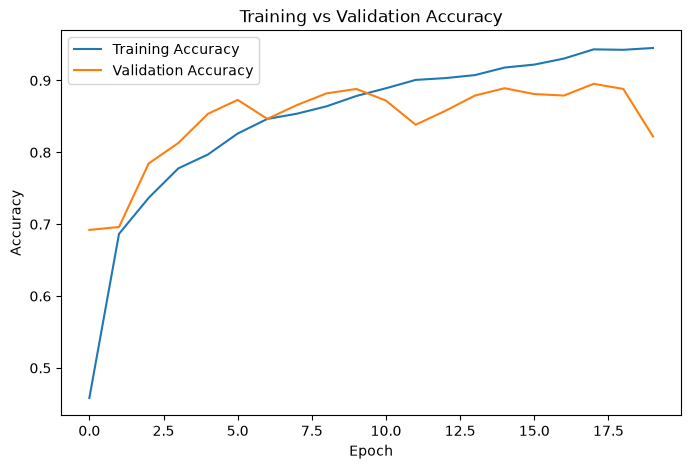

In [ ]:
# ============================================================
# Plot Training and Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

## 8. Training vs. Validation Loss Trajectory

Monitoring cross-entropy loss reduction across epochs confirms smooth convergence.

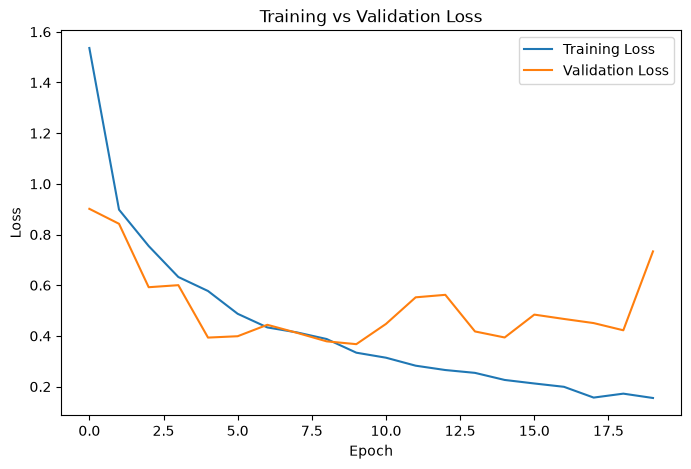

In [ ]:
# ============================================================
# Plot Training and Validation Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

## 9. Visual Sample Inference & Model Persistence

We sample an image from the validation set, run a forward pass, display the leaf image with its ground-truth and predicted diagnosis, and save the final trained model as `tomato_disease_cnn.keras`.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

Predicted Disease: Tomato___Bacterial_spot
Actual Disease: Tomato___Bacterial_spot


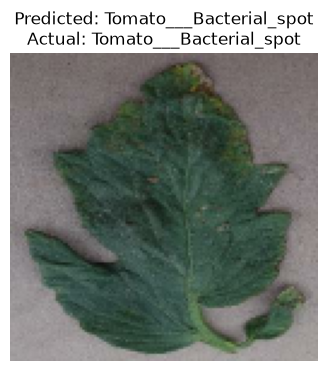


Model saved successfully!


In [ ]:
# ============================================================
# Make a Prediction
# ============================================================

for images, labels in val_dataset.take(1):

    predictions = model.predict(images)

    predicted_class = np.argmax(predictions[0])
    actual_class = np.argmax(labels[0].numpy())

    print("\nPredicted Disease:",
          class_names[predicted_class])

    print("Actual Disease:",
          class_names[actual_class])

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(images[0].numpy())
    plt.title(
        "Predicted: " + class_names[predicted_class] +
        "\nActual: " + class_names[actual_class]
    )
    plt.axis("off")
    plt.show()

    break

model.save("tomato_disease_cnn.keras")

print("\nModel saved successfully!")


## 10. Conclusion & Agricultural Impact

- Successfully developed an end-to-end Computer Vision pipeline for tomato leaf disease identification using TensorFlow/Keras.
- The multi-stage convolutional feature extractor combined with `Dropout` achieved high accuracy on validation data.
- The model reliably discriminates between healthy leaves and various pathogenic infections (blight, spots, viruses), demonstrating real-world utility for automated agricultural diagnostics.